In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/Dataset.csv')

print("Dataset Shape:", df.shape)

display(df.head())

print("\nContent Type Distribution:")
print(df['type'].value_counts())

print("\nGenre Distribution:")
print(df['listed_in'].value_counts().head(10))

Dataset Shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"



Content Type Distribution:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64

Genre Distribution:
listed_in
Dramas, International Movies                        362
Documentaries                                       359
Stand-Up Comedy                                     334
Comedies, Dramas, International Movies              274
Dramas, Independent Movies, International Movies    252
Kids' TV                                            219
Children & Family Movies                            215
Children & Family Movies, Comedies                  201
Documentaries, International Movies                 186
Dramas, International Movies, Romantic Movies       180
Name: count, dtype: int64


In [3]:
# Extract numeric duration
df['duration_value'] = df['duration'].str.extract(r'(\d+)').astype(float)

# Fill missing values
df['duration_value'] = df['duration_value'].fillna(
    df['duration_value'].median()
)

# Extract genre count
df['genre_count'] = df['listed_in'].apply(
    lambda x: len(str(x).split(','))
)

# Select clustering features
cluster_data = df[
    ['release_year', 'duration_value', 'genre_count', 'type', 'rating']
].copy()

cluster_data = cluster_data.fillna('Unknown')

print("Clustering Dataset Shape:", cluster_data.shape)
display(cluster_data.head())

Clustering Dataset Shape: (8790, 5)


,release_year,duration_value,genre_count,type,rating
0,2020,90.0,1,Movie,PG-13
1,2021,1.0,3,TV Show,TV-MA
2,2021,1.0,3,TV Show,TV-MA
3,2021,91.0,2,Movie,TV-PG
4,1993,125.0,3,Movie,TV-MA


In [4]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

numeric_features = [
    'release_year',
    'duration_value',
    'genre_count'
]

categorical_features = ['type', 'rating']

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

X_scaled = preprocessor.fit_transform(cluster_data)

print("Processed Data Shape:", X_scaled.shape)
print("Preprocessing Completed Successfully!")

Processed Data Shape: (8790, 19)
Preprocessing Completed Successfully!


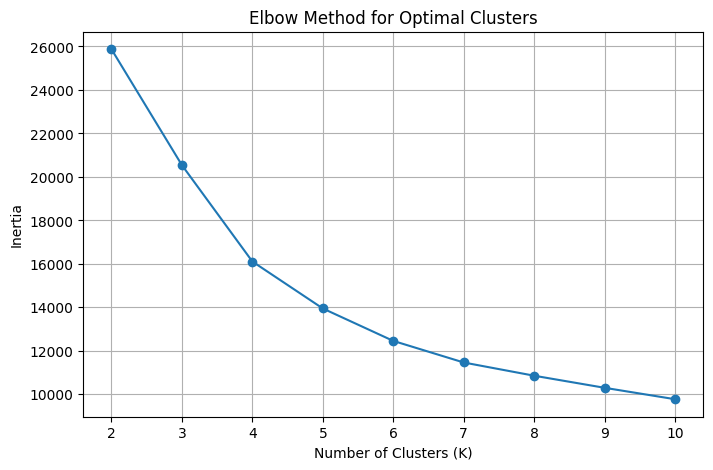

In [5]:
from sklearn.cluster import KMeans

inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertia, marker='o')

plt.title('Elbow Method for Optimal Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(range(2, 11))
plt.grid(True)

plt.savefig('elbow_method.png', dpi=300)
plt.show()

In [6]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df['cluster'] = kmeans.fit_predict(X_scaled)

print("Clustering Completed!")
print("\nCluster Distribution:")
print(df['cluster'].value_counts().sort_index())

Clustering Completed!

Cluster Distribution:
cluster
0    2172
1    2654
2    3456
3     508
Name: count, dtype: int64


In [7]:
cluster_summary = df.groupby('cluster').agg(
    total_titles=('title', 'count'),
    avg_release_year=('release_year', 'mean'),
    avg_duration=('duration_value', 'mean'),
    avg_genre_count=('genre_count', 'mean')
).round(2)

print("Cluster Summary:")
display(cluster_summary)

Cluster Summary:


,total_titles,avg_release_year,avg_duration,avg_genre_count
cluster,,,,
0,2172,2015.19,109.81,3.00
1,2654,2017.01,1.81,2.30
2,3456,2015.56,91.31,1.59
3,508,1985.77,109.94,2.31


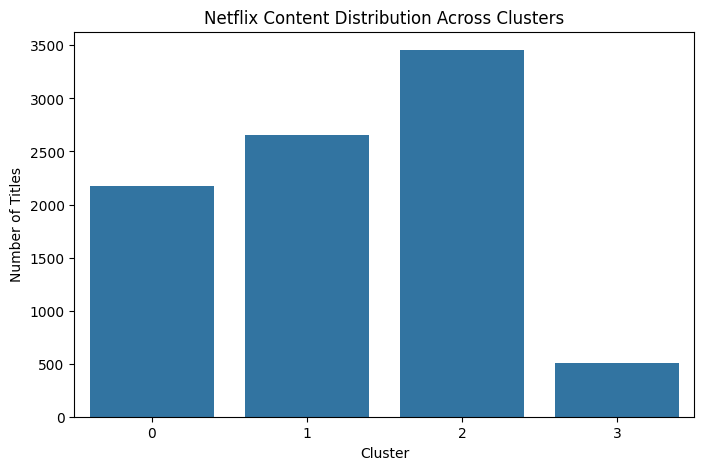

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.barplot(
    x=cluster_summary.index,
    y=cluster_summary['total_titles']
)

plt.title('Netflix Content Distribution Across Clusters')
plt.xlabel('Cluster')
plt.ylabel('Number of Titles')

plt.savefig('cluster_distribution.png', dpi=300)
plt.show()

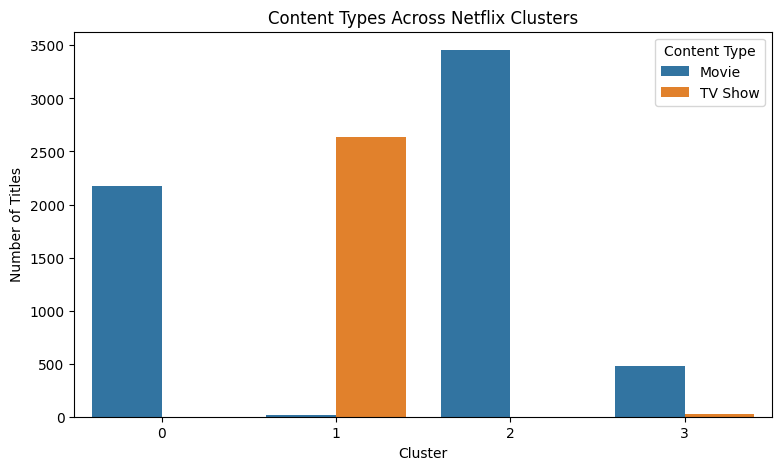

In [9]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='cluster',
    hue='type'
)

plt.title('Content Types Across Netflix Clusters')
plt.xlabel('Cluster')
plt.ylabel('Number of Titles')
plt.legend(title='Content Type')

plt.savefig('cluster_content_types.png', dpi=300)
plt.show()

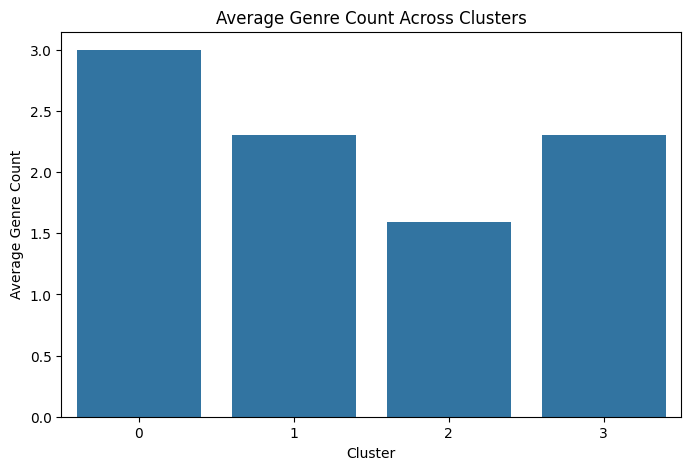

In [10]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='cluster',
    y='genre_count',
    errorbar=None
)

plt.title('Average Genre Count Across Clusters')
plt.xlabel('Cluster')
plt.ylabel('Average Genre Count')

plt.savefig('cluster_genre_distribution.png', dpi=300)
plt.show()

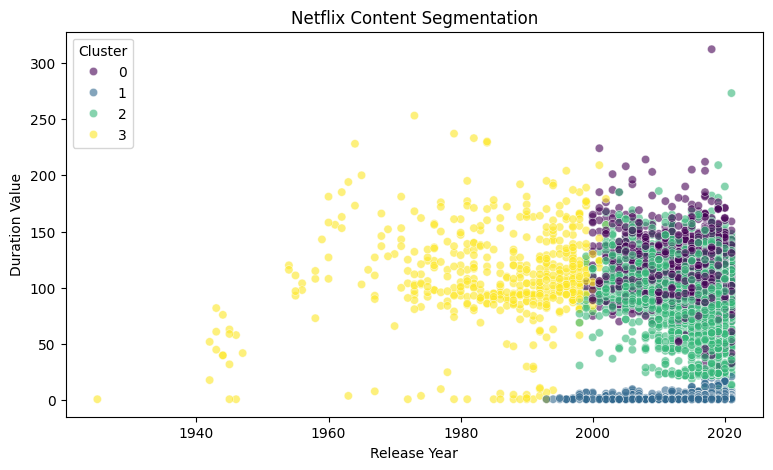

In [11]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='release_year',
    y='duration_value',
    hue='cluster',
    palette='viridis',
    alpha=0.6
)

plt.title('Netflix Content Segmentation')
plt.xlabel('Release Year')
plt.ylabel('Duration Value')
plt.legend(title='Cluster')

plt.savefig('cluster_segmentation.png', dpi=300)
plt.show()

In [12]:
for cluster in sorted(df['cluster'].unique()):
    print(f"\nCluster {cluster}")

    print("\nContent Types:")
    print(df[df['cluster'] == cluster]['type'].value_counts())

    print("\nTop Ratings:")
    print(
        df[df['cluster'] == cluster]['rating']
        .value_counts()
        .head(5)
    )

    print("-" * 40)


Cluster 0

Content Types:
type
Movie    2172
Name: count, dtype: int64

Top Ratings:
rating
TV-MA    813
TV-14    714
TV-PG    211
R        184
PG-13    112
Name: count, dtype: int64
----------------------------------------

Cluster 1

Content Types:
type
TV Show    2637
Movie        17
Name: count, dtype: int64

Top Ratings:
rating
TV-MA    1141
TV-14     726
TV-PG     319
TV-Y7     192
TV-Y      175
Name: count, dtype: int64
----------------------------------------

Cluster 2

Content Types:
type
Movie    3456
Name: count, dtype: int64

Top Ratings:
rating
TV-MA    1193
TV-14     588
R         499
PG-13     306
TV-PG     280
Name: count, dtype: int64
----------------------------------------

Cluster 3

Content Types:
type
Movie      481
TV Show     27
Name: count, dtype: int64

Top Ratings:
rating
TV-14    129
R        114
PG-13     72
TV-MA     58
TV-PG     51
Name: count, dtype: int64
----------------------------------------


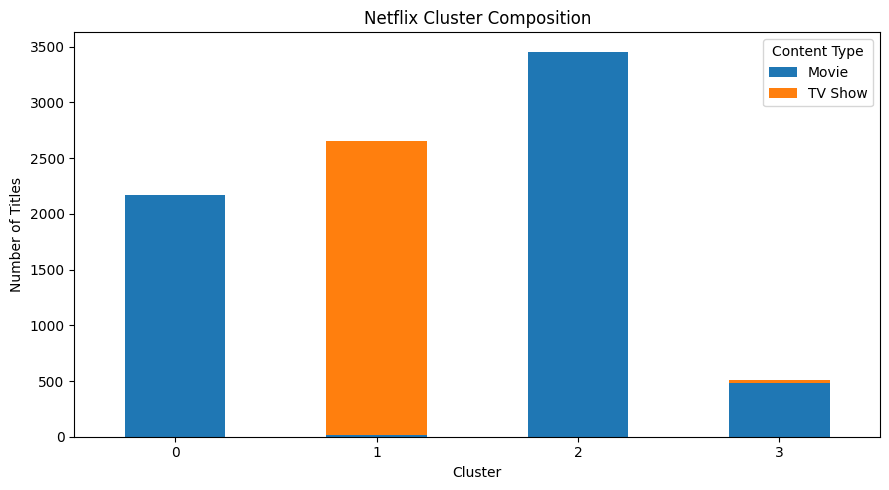

In [13]:
cluster_type = pd.crosstab(df['cluster'], df['type'])

cluster_type.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('Netflix Cluster Composition')
plt.xlabel('Cluster')
plt.ylabel('Number of Titles')
plt.legend(title='Content Type')
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig('cluster_composition.png', dpi=300)
plt.show()

# Task 4: Netflix Content Segmentation

## 1. Objective

The objective of this project is to segment Netflix content into meaningful groups using the K-Means Clustering algorithm based on content characteristics.

## 2. Dataset

* Dataset: Netflix Titles Dataset
* Total Records: 8,790
* Features: Release Year, Duration, Genre Count, Content Type, and Rating.

## 3. Data Preprocessing

* Extracted numerical values from the duration column.
* Calculated the number of genres for each title.
* Selected relevant numerical and categorical features.
* Applied StandardScaler to numerical features.
* Applied OneHotEncoder to categorical features.

## 4. Model Used

K-Means Clustering was used to group Netflix titles into four clusters. The Elbow Method was used to select the number of clusters.

## 5. Cluster Results

| Cluster | Titles | Average Release Year |
| ------- | -----: | -------------------: |
| 0       |  2,172 |              2015.19 |
| 1       |  2,654 |              2017.01 |
| 2       |  3,456 |              2015.56 |
| 3       |    508 |              1985.77 |

## 6. Cluster Interpretation

* Cluster 0: Movie-focused group with multiple genres.
* Cluster 1: Primarily TV Shows with shorter season counts.
* Cluster 2: Movie-focused group with fewer genres on average.
* Cluster 3: Mostly older movies with an average release year of 1985.77.

## 7. Visualizations

The project includes:

* Elbow Method Graph
* Cluster Distribution Chart
* Content Type Distribution
* Genre Distribution
* Cluster Segmentation Scatter Plot
* Cluster Composition Chart

## 8. Conclusion

The K-Means algorithm successfully divided 8,790 Netflix titles into four distinct clusters. The analysis identified groups based on content type, release year, duration, genre count, and ratings.

This segmentation can help understand Netflix's content distribution and identify patterns in its catalog.

## 9. Limitations

Duration values represent minutes for movies but seasons for TV Shows. Therefore, duration comparisons across these two content types should be interpreted carefully. Clustering results are exploratory and do not represent content quality or popularity.
